# Multiplier intrinsic metrics (NAME + LUT error)

Multiplier-only analysis: no neural network, no sweep results. Everything is
computed in Python from the recursive composition (the same engine as
`0_build_multipliers`), so the notebook is self-contained (numpy + matplotlib).

1. **NAME** — the AMPEREISH paper's Table 6 metric: the normalised *mean signed
   error* of each multiplier under the paper's Gaussian operand model. Computed
   **exactly** as a closed-form weighted sum over all 65,536 operand pairs, which
   resolves the heavily self-healed designs (ISH4/ISH5) that Monte-Carlo at the
   paper's sample size cannot.
2. **Convergence** — Monte-Carlo estimates at growing sample size, shown
   approaching the exact value (and where the paper's N=100k lands).
3. **LUT error metrics** — ER / MAE / WCE / MSE / MRED / NMED / bias of each
   multiplier's 256×256 table against the exact reference.

In [1]:
import re, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def _first(paths, needs):
    for p in paths:
        p = Path(p)
        if (p / needs).exists():
            return p
    return None

# Results root (for exporting the metrics table) and the signed LUT headers (for the
# LUT-error section). adapt/transaxx hold identical multipliers. The split only
# matters for the consuming framework.
def find_results_root():
    for c in (Path("../results"), Path("results"), Path("../../docker/results")):
        if (c / "adapt").exists() or (c / "transaxx").exists():
            return c
    raise FileNotFoundError("results/ not found -- run a sweep notebook first")

ROOT = find_results_root()
OUT = ROOT / "metrics"
OUT.mkdir(parents=True, exist_ok=True)

# Prefer the built-LUT dir (docker/luts) -- it holds *every* multiplier, including
# python-only ones like mul8s_1l2h. Fall back to the baked C dir (exact + fpga only).
LUT_DIR = None
for _fw in ("adapt", "transaxx"):
    LUT_DIR = _first([f"/work/luts/{_fw}", f"../luts/{_fw}",
                      f"/workspace/multipliers/luts/{_fw}",
                      f"../../multipliers/luts/{_fw}"], "mul8s_exact.h")
    if LUT_DIR is not None:
        break

# The LUT-error table auto-includes every mul8s_*.h in LUT_DIR except these.
# mul8s_acc is the exact baseline (== the reference, MAE 0); mul8s_1l2h_shipped is
# AdaPT's broken bundled 1L2H (a demoted validation artifact, not a baseline).
EXCLUDE_MULTS = ("mul8s_acc", "mul8s_1l2h_shipped")

print("exports ->", OUT.resolve())
print("LUT headers:", LUT_DIR.resolve() if LUT_DIR else "not found (LUT-error section will skip)")

exports -> /work/results/metrics
LUT headers: /work/luts/adapt


## NAME vs the paper (Table 6)

**NAME = |mean(approx − exact)| / 2¹⁶**, with operands drawn independently from
`clip(round(N(μ=128, σ=22.5)), 0, 255)`, which is the operand model in the AMPEREISH
paper. Note it is the *mean signed* error (a bias), not the mean absolute error.

Because the operand space is finite (256×256), this expectation is a closed-form
weighted sum over all 65,536 pairs, so we compute it **exactly** (zero sampling
noise). `ratio = exact / paper` near 1.0 means we reproduce the paper. The engine
below mirrors `0_build_multipliers`. An assertion checks it reproduces `a·b`
exactly over the full unsigned range before any NAME is computed.

In [2]:
# --- Recursive composition engine (mirror of 0_build_multipliers / compose.c).
# Unsigned 8-bit products over operands 0..255, which is what NAME uses. (This is
# the UNSIGNED path. The signed LUT headers only cover magnitudes 0..128, so the
# products are re-derived here rather than read from the LUT.)
PRIMITIVES = {
    "m5": np.array([[0,0,0,0],[0,1,2,3],[0,2,4,6],[0,3,6,9]]),
    "m1": np.array([[0,0,0,0],[0,1,2,3],[0,2,4,6],[0,3,6,7]]),
    "m2": np.array([[0,0,0,0],[0,0,2,2],[0,2,4,6],[0,2,6,9]]),
    "m3": np.array([[0,0,0,0],[0,1,2,3],[0,2,4,6],[0,3,6,11]]),
    "m4": np.array([[0,0,0,0],[0,1,2,3],[0,2,4,6],[0,3,6,5]]),
}
BLOCKS = {
    "exact":      {"HH": "m5", "HL": "m5", "LH": "m5", "LL": "m5"},
    "block_1311": {"HH": "m1", "HL": "m3", "LH": "m1", "LL": "m1"},
    "block_1315": {"HH": "m1", "HL": "m3", "LH": "m1", "LL": "m5"},
    "block_4335": {"HH": "m4", "HL": "m3", "LH": "m3", "LL": "m5"},
}
SPECS = {
    "FPGA_ISH_1": {"HH": "block_1311", "HL": "block_1311", "LH": "block_1311", "LL": "block_1311"},
    "FPGA_ISH_2": {"HH": "block_1315", "HL": "block_1311", "LH": "block_1311", "LL": "block_1311"},
    "FPGA_ISH_3": {"HH": "block_4335", "HL": "block_1315", "LH": "block_1311", "LL": "block_1311"},
    "FPGA_ISH_4": {"HH": "block_4335", "HL": "block_1315", "LH": "block_1315", "LL": "block_1311"},
    "FPGA_ISH_5": {"HH": "block_4335", "HL": "block_1315", "LH": "block_1315", "LL": "block_1315"},
}

_n4 = np.arange(16)
_h4, _l4 = (_n4 >> 2) & 3, _n4 & 3          # 2-bit halves of a 4-bit value

def _block_table(block):
    """16x16 table of the (approximate) 4-bit product, table[x, y]."""
    P = {q: PRIMITIVES[block[q]] for q in ("HH", "HL", "LH", "LL")}
    XH, XL = _h4[:, None], _l4[:, None]
    YH, YL = _h4[None, :], _l4[None, :]
    return 16*P["HH"][XH, YH] + 4*P["HL"][XH, YL] + 4*P["LH"][XL, YH] + 1*P["LL"][XL, YL]

_n8 = np.arange(256)
_h8, _l8 = (_n8 >> 4) & 0xF, _n8 & 0xF      # 4-bit halves of an 8-bit value

def product_table(spec):
    """256x256 table of the unsigned 8-bit (approximate) product, table[a, b]."""
    B = {q: _block_table(BLOCKS[spec[q]]) for q in ("HH", "HL", "LH", "LL")}
    AH, AL = _h8[:, None], _l8[:, None]
    BH, BL = _h8[None, :], _l8[None, :]
    return 256*B["HH"][AH, BH] + 16*B["HL"][AH, BL] + 16*B["LH"][AL, BH] + 1*B["LL"][AL, BL]

EXACT = np.outer(_n8, _n8)                  # the true product a*b
assert (product_table({q: "exact" for q in ("HH", "HL", "LH", "LL")}) == EXACT).all(), \
    "composition engine does not reproduce exact products over 0..255"

err_tables = {name: product_table(spec) - EXACT for name, spec in SPECS.items()}

# --- Operand model from the AMPEREISH paper: each operand is an unsigned byte
# clip(round(N(mu, sigma)), 0, 255), drawn independently.
MU, SIGMA = 128.0, 22.5

def _gaussian_byte_pmf(mu, sigma):
    """Exact PMF over bytes 0..255 of clip(round(N(mu, sigma)), 0, 255)."""
    cdf = np.vectorize(lambda t: 0.5 * (1.0 + math.erf((t - mu) / (sigma * math.sqrt(2.0)))))
    lo = (np.arange(256) - 0.5).astype(float); lo[0]  = -np.inf   # r=0 absorbs the low clip
    hi = (np.arange(256) + 0.5).astype(float); hi[-1] =  np.inf   # r=255 absorbs the high clip
    pmf = cdf(hi) - cdf(lo)
    return pmf / pmf.sum()

pmf = _gaussian_byte_pmf(MU, SIGMA)
W = np.outer(pmf, pmf)                       # joint weight P(a) * P(b)

# NAME computed EXACTLY: |E[approx - exact]| / 2^16 as a weighted sum over all
# 65,536 pairs -- zero variance, resolves even ISH5.
PAPER = {"FPGA_ISH_1": 7.19e-4, "FPGA_ISH_2": 1.18e-4, "FPGA_ISH_3": 3.47e-5,
         "FPGA_ISH_4": 2.47e-6, "FPGA_ISH_5": 5.74e-7}
exact_name = {name: abs(float((W * D).sum())) / 65536.0 for name, D in err_tables.items()}

# Export table: presentation-formatted so the CSV renders cleanly.
report = pd.DataFrame({
    "Design":     list(SPECS),
    "Paper NAME": [f"{PAPER[n]:.2e}" for n in SPECS],
    "Exact NAME": [f"{exact_name[n]:.2e}" for n in SPECS],
    "Ratio":      [f"{exact_name[n] / PAPER[n]:.2f}" for n in SPECS],
})
report.to_csv(OUT / "name_vs_paper.csv", index=False)
print("wrote", OUT / "name_vs_paper.csv")

# Full precision for inspection.
display(pd.DataFrame({"spec": list(SPECS),
                      "paper": [PAPER[n] for n in SPECS],
                      "exact": [exact_name[n] for n in SPECS],
                      "ratio": [exact_name[n] / PAPER[n] for n in SPECS]}))

wrote ../results/metrics/name_vs_paper.csv


,spec,paper,exact,ratio
0,FPGA_ISH_1,7.190000e-04,7.065804e-04,0.982727
1,FPGA_ISH_2,1.180000e-04,1.099203e-04,0.931528
2,FPGA_ISH_3,3.470000e-05,3.570874e-05,1.029070
3,FPGA_ISH_4,2.470000e-06,1.973910e-06,0.799154
4,FPGA_ISH_5,5.740000e-07,6.656176e-08,0.115961


## Convergence: Monte-Carlo → exact

Why exact matters most for the self-healed designs: NAME is a near-cancelling
*signed* mean, so its Monte-Carlo standard error is large relative to the value
when the design heals well (ISH4/ISH5). Below, the sampled estimate (mean ± std
over trials) approaches the exact value (dashed) as N grows. The dotted line marks
the paper's N=100k. ISH1–3 settle quickly. ISH5 stays noisy well past 100k, which is
exactly why the exact computation is the trustworthy number.

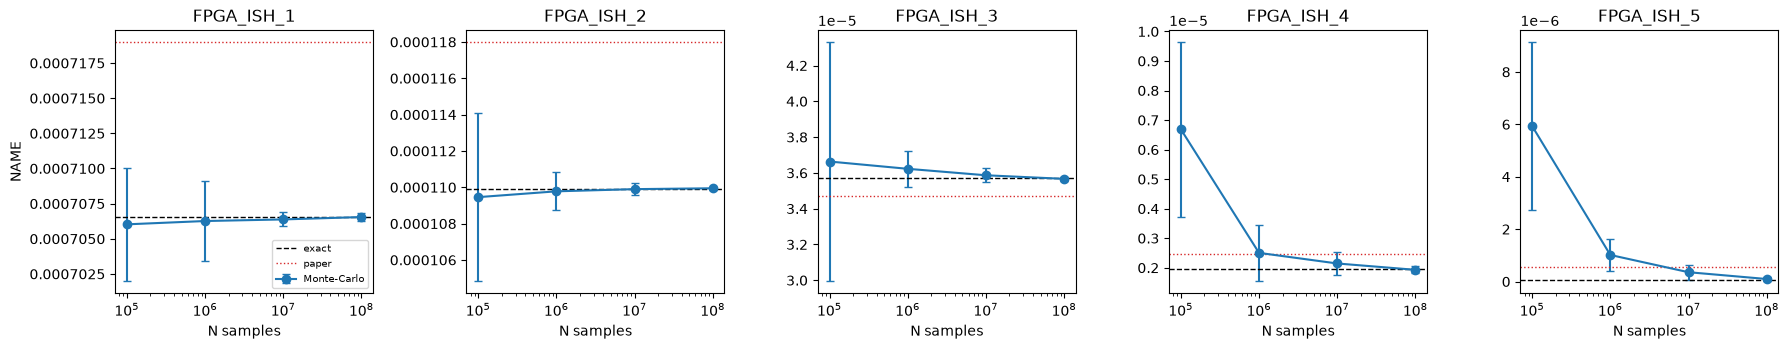

In [3]:
rng = np.random.default_rng(0)

def sample_bytes(n):
    return np.clip(np.round(rng.normal(MU, SIGMA, n)).astype(np.int64), 0, 255)

SWEEP_N = [100_000, 1_000_000, 10_000_000, 100_000_000]   # lower the top value if this is slow
M = 10                                       # trials per N, for the error bar

mc = {name: [] for name in SPECS}            # name -> [(N, mean, std), ...]
for N in SWEEP_N:
    per = {name: [] for name in SPECS}
    for _ in range(M):
        a, b = sample_bytes(N), sample_bytes(N)
        for name, D in err_tables.items():
            per[name].append(abs(float(D[a, b].mean())) / 65536.0)
    for name in SPECS:
        v = np.array(per[name])
        mc[name].append((N, v.mean(), v.std()))

fig, axes = plt.subplots(1, len(SPECS), figsize=(3.6 * len(SPECS), 3.6))
for ax, name in zip(axes, SPECS):
    Ns, means, stds = zip(*mc[name])
    ax.errorbar(Ns, means, yerr=stds, marker="o", capsize=3, label="Monte-Carlo")
    ax.axhline(exact_name[name], ls="--", color="k", lw=1, label="exact")
    ax.axhline(PAPER[name], ls=":", color="C3", lw=1, label="paper")
    ax.set_xscale("log")
    ax.set_title(name)
    ax.set_xlabel("N samples")
axes[0].set_ylabel("NAME")
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "name_convergence.png", dpi=120, bbox_inches="tight")
plt.show()

## LUT error metrics

Pure-numpy diff of each multiplier's 256x256 header against the exact reference
(`mul8s_exact`). Operands are read as unsigned bytes then reinterpreted signed,
matching how AdaPT / TransAxx index the table.

In [4]:
if LUT_DIR is None:
    print("no LUT headers found -- run multipliers/generate/build_all.sh first.")
else:
    def load_lut(name):
        text = (LUT_DIR / f"{name}.h").read_text()
        nums = re.findall(r"-?\d+", text.split("{", 1)[1])
        return np.array(nums, dtype=np.int16).reshape(256, 256)

    def signed_view(lut):
        order = np.argsort(np.r_[0:128, -128:0])
        return lut[np.ix_(order, order)]

    def lut_metrics(name, ref="mul8s_exact"):
        L = signed_view(load_lut(name)).astype(np.int32)
        R = signed_view(load_lut(ref)).astype(np.int32)
        err = L - R
        abs_err = np.abs(err).astype(np.float64)
        nonzero = R != 0
        rel = np.divide(abs_err, np.abs(R), out=np.zeros_like(abs_err), where=nonzero)
        return {"name": name,
                "ER": float((err != 0).mean()),
                "MAE": float(abs_err.mean()),
                "WCE": int(np.abs(err).max()),
                "MSE": float((err.astype(np.float64) ** 2).mean()),
                "MRED": float(rel[nonzero].mean()),
                "NMED": float(abs_err.mean() / (127 * 127)),
                "bias": float(err.mean())}

    # Auto-discover every multiplier in LUT_DIR (vs the exact reference), minus the
    # exclude list. fpga_ish first by number, then anything else (e.g. mul8s_1l2h).
    ref = "mul8s_exact"
    names = [p.stem for p in LUT_DIR.glob("mul8s_*.h")
             if p.stem != ref and p.stem not in EXCLUDE_MULTS]
    names.sort(key=lambda s: (0, int(re.search(r"fpga_ish_(\d+)", s).group(1)))
                             if re.search(r"fpga_ish_(\d+)", s) else (1, s))

    metrics_df = pd.DataFrame([lut_metrics(n, ref) for n in names]).round(6)
    metrics_df.to_csv(OUT / "lut_error_metrics.csv", index=False)
    print("wrote", OUT / "lut_error_metrics.csv")
    display(metrics_df)

wrote ../results/metrics/lut_error_metrics.csv


,name,ER,MAE,WCE,MSE,MRED,NMED,bias
0,mul8s_fpga_ish_1,0.334229,49.149414,714,19740.25,0.013288,0.003047,0.00
1,mul8s_fpga_ish_2,0.314453,19.818359,202,2196.25,0.008061,0.001229,0.00
2,mul8s_fpga_ish_3,0.288086,18.137695,170,2024.25,0.007219,0.001125,0.00
3,mul8s_fpga_ish_4,0.261719,17.075195,168,2040.25,0.006552,0.001059,0.00
4,mul8s_fpga_ish_5,0.226562,17.000000,168,2039.50,0.006434,0.001054,0.00
5,mul8s_1kva,0.500000,1.250000,5,3.75,0.002752,0.000078,-1.25
6,mul8s_1kvb,0.687500,4.250000,17,34.25,0.009024,0.000264,-4.25
7,mul8s_1l2h,0.746094,53.333984,255,5461.75,0.044120,0.003307,0.75
